In [1]:
# Execute a general setup notebook which likely contains common imports, helper functions, and consistent plotting styles.
%run general.ipynb

# Enable inline plotting for matplotlib to display plots directly within the notebook.
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

RESULTS_DIR = '../results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print(f'Output directory: {RESULTS_DIR}')


/home/software/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_repeats=1, random_state=None as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "
/home/software/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_splits=3, n_repeats=1 as keyword args. From version 1.0 (renaming of 0.25) passing these as positional arguments will result in an error
  warnings.warn(f"Pass {args_msg} as keyword args. From version "


2026-11-02 00:44:54 WARNING These have metadata but do not have data - dropped (415): {'surface.ctrl.TE.05.18.16.plastic.1', 'H2.skin.TE.09.14.15.4p.5xtouch.plastic.3', 'H3.skin.TE.09.14.15.1p.metal.2', 'BLANK5.5A', 'ctrl.swab.3.201509', 'H2.skin.TE.09.14.15.1p.glass.4', 'BLANK8.7G', 'H43.skin.9.12.17.Rpalm', 'surface.ctrl.TE.09.14.15.11a.metal.4', 'BLANK.3.F3', 'surface.ctrl.TE.09.14.15.4p.plastic.4', 'H1.skin.TE.09.14.15.3p.plastic.4', 'BLANK.4.C8', 'BLANK13.4.5H', 'surface.ctrl.TE.09.14.15.1p.glass.3', 'BLANK10.10B', 'H2.skin.TE.09.14.15.11a.metal.4', 'H3.skin.TE.09.14.15.11a.glass.1', 'H3.skin.TE.09.14.15.1p.plastic.2', 'H5.skin.TE.09.14.15.11a.glass.2', 'BLANK.4.G7', 'surface.ctrl.TE.09.14.15.4p.glass.1', 'H2.skin.TE.09.14.15.11a.metal.3', 'BLANK8.3C', 'H9.surface.10x.TE.03.16.16.metal.4', 'surface.ctrl.TE.09.14.15.1p.metal.5', 'BLANK8.4F', 'BLANK12.C11', 'BLANK8.11C', 'BLANK4.4C', 'BLANK.2.A2', 'surface.ctrl.TE.09.14.15.11a.glass.4', 'BLANK8.7E', 'H51.skin.20x.9.15.17.plastic', '

### Part 4: Touch Order Effect Analysis (**Mixed Signal**)

This is a more complex experiment simulating **two people** touching the same surface sequentially.

In [2]:
mat_color_dict = MAT_COLOR_DICT
exp_mixed_signal = exp .filter_samples('experiment_category', 'mixed_signal')
exp_mixed_signal

AmpliconExperiment ("reference-hit.2026.biom") with 164 samples, 10511 features

In [3]:
# Filter for samples from the mixed-signal experiment, where metadata explicitly marks the first toucher ('pair1_resident') and the second toucher ('pair2_perp').
paired_samples = exp_mixed_signal.reorder(exp_mixed_signal.sample_metadata.pair1_resident.notnull())
paired_samples.sample_metadata['pair'] = [i.split('.')[1] for i in paired_samples.sample_metadata.index]
paired_samples = paired_samples.sort_samples('pair').sort_samples('surface_type')
paired_samples.sample_metadata.head()

,experiment,experiment_category,individual,pair1_resident,pair2_perp,replicate_order,sample_type,surface_type,touches,persistence_time_sec,sample_date,month,year,day,_sample_id,_calour_original_abundance,pair
#SampleID,,,,,,,,,,,,,,,,,
surface.pair1.10.18.16.ceramic,exp201610,mixed_signal,pair_H8H1,H8,H1,NaN,surface_touched,ceramic,50,NaN,20161018.0,10.0,2016.0,18.0,surface.pair1.10.18.16.ceramic,25324.0,pair1
surface.pair1.10.19.16.ceramic,exp201610,mixed_signal,pair_H8H1,H1,H8,NaN,surface_touched,ceramic,50,NaN,20161019.0,10.0,2016.0,19.0,surface.pair1.10.19.16.ceramic,20524.0,pair1
surface.pair2.10.18.16.ceramic,exp201610,mixed_signal,pair_H32H15,H32,H15,NaN,surface_touched,ceramic,50,NaN,20161018.0,10.0,2016.0,18.0,surface.pair2.10.18.16.ceramic,26466.0,pair2
surface.pair2.10.19.16.ceramic,exp201610,mixed_signal,pair_H32H15,H15,H32,NaN,surface_touched,ceramic,50,NaN,20161019.0,10.0,2016.0,19.0,surface.pair2.10.19.16.ceramic,15944.0,pair2
surface.pair3.10.18.16.ceramic,exp201610,mixed_signal,pair_H35H31,H35,H31,NaN,surface_touched,ceramic,50,NaN,20161018.0,10.0,2016.0,18.0,surface.pair3.10.18.16.ceramic,27423.0,pair3


In [4]:
hosts_mixed_signal = list(set(paired_samples.sample_metadata.pair1_resident))

In [5]:
# The training set consists of the personal skin samples of the participants.
train_set_mixed = exp_mixed_signal.filter_samples('individual', hosts_mixed_signal).filter_by_metadata('_calour_original_abundance', select=lambda i: i > 500)
print(f"Training set shape: {train_set_mixed.shape}")

# The test set consists of the mixed microbial samples left after two individuals touched the surface.
test_set_mixed = paired_samples.filter_ids(train_set_mixed.feature_metadata.index, axis=1).filter_by_metadata('_calour_original_abundance', select=lambda i: i > 200)
print(f"Test set shape: {test_set_mixed.shape}")

Training set shape: (60, 10511)
Test set shape: (24, 10511)


In [6]:
metadata_train = train_set_mixed.sample_metadata
hosts_on_surfaces_train = set(metadata_train.query('experiment_category=="mixed_signal" & sample_type=="skin"')['individual'].unique())
print(f"Number of train hosts found: {len(hosts_on_surfaces_train)}")
print(f"Train hosts: {hosts_on_surfaces_train}")

Number of train hosts found: 12
Train hosts: {'H35', 'H23', 'H34', 'H32', 'H1', 'H27', 'H33', 'H8', 'H28', 'H36', 'H15', 'H31'}


In [7]:
X_train_mixed, y_train_mixed = train_set_mixed.data, train_set_mixed.sample_metadata.individual

print("Training RandomForest...")
rf_model_mixed = RandomForestClassifier(n_estimators=500, oob_score=True)
rf_model_mixed.fit(X_train_mixed, y_train_mixed)
print(f"RandomForest OOB Score: {rf_model_mixed.oob_score_}")

print("\nTraining QDA...")
qda_model_mixed = QuadraticDiscriminantAnalysis()
qda_model_mixed.fit(X_train_mixed.toarray(), y_train_mixed)

print("\nTraining GaussianNB...")
gnb_model_mixed = GaussianNB()
gnb_model_mixed.fit(X_train_mixed.toarray(), y_train_mixed)

print("\nTraining SVC...")
svc_model_mixed = SVC(probability=True)
svc_model_mixed.fit(X_train_mixed.toarray(), y_train_mixed)

print("\nTraining GaussianProcessClassifier...")
gpc_model_mixed = GaussianProcessClassifier(1.0 * RBF(1.0))
gpc_model_mixed.fit(X_train_mixed.toarray(), y_train_mixed)

Training RandomForest...
RandomForest OOB Score: 0.9333333333333333

Training QDA...

Training GaussianNB...

Training SVC...


/home/software/anaconda3/envs/qiime2-2022.2/lib/python3.8/site-packages/sklearn/discriminant_analysis.py:808: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")



Training GaussianProcessClassifier...


GaussianProcessClassifier(kernel=1**2 * RBF(length_scale=1))

In [8]:
grid_search_mixed = make_rf_grid_search()
saved_model_path_mixed = os.path.join(RESULTS_DIR, 'mixed-signal-model.pkl.bz2')
best_model_mixed = load_or_fit_model(grid_search_mixed, saved_model_path_mixed, X_train_mixed, y_train_mixed)

Loading pre-trained model from ../results/mixed-signal-model.pkl.bz2...


In [9]:
ordered_hosts = paired_samples.sample_metadata.query('surface_type=="ceramic"')['pair1_resident']

y_prob_mixed = pd.DataFrame(best_model_mixed.predict_proba(test_set_mixed.data.toarray()),
                            index=paired_samples.sample_metadata.index,
                            columns=best_model_mixed.classes_)[ordered_hosts]

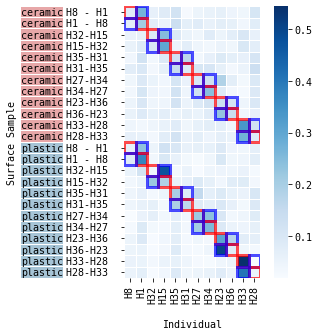

In [10]:
# Visualization: Heatmap ---
outcomes = y_prob_mixed.columns.tolist()

plt.rc('font', **{'family': 'monospace'})
fig_heatmap_mixed_signal, ax_heatmap = plt.subplots(figsize=(5,5))

sns.heatmap(y_prob_mixed, xticklabels=True, linewidths=1, square=True, ax=ax_heatmap, cmap="Blues")

ax_heatmap.set_xticklabels(outcomes, rotation=90)

materials = paired_samples.sample_metadata.surface_type
samples = paired_samples.sample_metadata.pair1_resident.str.ljust(3) + '-' + paired_samples.sample_metadata.pair2_perp.str.rjust(3)
full_labels = materials + ' ' + samples

ax_heatmap.set_yticklabels(labels=full_labels, rotation=0, color='none')

trans = ax_heatmap.get_yaxis_transform()

split_x = -0.15

for i, (mat, samp) in enumerate(zip(materials, samples)):
    facecolor = '#E59E9F' if mat == 'ceramic' else '#9DBED2'
    
    ax_heatmap.text(
        x=split_x-0.3, y=i + 0.5, s=mat, 
        ha='right', va='center', transform=trans,
        bbox=dict(facecolor=facecolor, edgecolor='none', alpha=0.9, pad=0.2)
    )
    
    ax_heatmap.text(
        x=split_x-0.32, y=i + 0.5, s=' ' + samp, 
        ha='left', va='center', transform=trans
    )
for i, sid in enumerate(y_prob_mixed.index):
    p = paired_samples.sample_metadata.loc[sid, 'pair1_resident']
    s = paired_samples.sample_metadata.loc[sid, 'pair2_perp']
    pi, si = outcomes.index(p), outcomes.index(s)
    
    ax_heatmap.add_patch(Rectangle((pi, i), 1, 1, fill=False, edgecolor='red', lw=3, alpha=0.7))
    ax_heatmap.add_patch(Rectangle((si, i), 1, 1, fill=False, edgecolor='blue', lw=3, alpha=0.7))

ax_heatmap.set_ylabel('Surface Sample',labelpad=10)
ax_heatmap.set_xlabel('Individual')

import matplotlib.transforms as mtransforms
trans = mtransforms.blended_transform_factory(ax_heatmap.transData, ax_heatmap.transAxes)
ax_heatmap.xaxis.set_label_coords(len(outcomes)/2, -0.15, transform=trans)

plt.show()

In [11]:
d = RESULTS_DIR
save_fig(fig_heatmap_mixed_signal, os.path.join(d, '201610.mixed-signal.heatmap.boxed.no-mitochondria.pdf'))

In [12]:
jk_cache_path = os.path.join(RESULTS_DIR, 'mixed-signal-jackknife.pkl.bz2')
surface_types = ['ceramic', 'plastic']
roles = ['1st subject', '2nd subject']
role_keys = {'1st subject': 'pair1_resident', '2nd subject': 'pair2_perp'}
mat_to_i = {m: i for i, m in enumerate(surface_types)}
role_to_j = {r: j for j, r in enumerate(roles)}

def mixed_signal_jk_contrib(md, **ctx):
    mat_i = mat_to_i.get(md['surface_type'], -1)
    if mat_i < 0:
        return []
    contributions = []
    for role_name in roles:
        obs = md[role_keys[role_name]]
        if obs in best_model_mixed.classes_:
            contributions.append({
                'group_index': (mat_i, role_to_j[role_name]),
                'target': obs,
            })
    return contributions

jackknife_results5 = compute_cached_jackknife_tensor(
    model=best_model_mixed,
    X=test_set_mixed.data,
    sample_metadata=paired_samples.sample_metadata,
    contribution_getter=mixed_signal_jk_contrib,
    class_labels=best_model_mixed.classes_,
    max_N=12,
    progress_every=10,
    tensor_shape=(len(surface_types), len(roles)),
    cache_path=jk_cache_path,
    bar_key='jk5_bar',
    topn_key='jk5_topn',
    cache_extras={
        'surface_types': surface_types,
        'roles': roles,
    },
)

surface_types = jackknife_results5['surface_types']
roles = jackknife_results5['roles']
jk5_bar = jackknife_results5['jk5_bar']
jk5_topn = jackknife_results5['jk5_topn']
max_N = jackknife_results5['max_N']

print("Top-3 Accuracy (Jackknife mean ± SE):")
for mat_i, mat in enumerate(surface_types):
    for role_j, role_name in enumerate(roles):
        mask = paired_samples.sample_metadata['surface_type'].eq(mat).to_numpy()
        role_stats = compute_masked_jackknife_topn_stats(jk5_bar, mask, mat_i, role_j)
        print(f"  {mat} {role_name}: {role_stats['means'][2]:.4f} ± {role_stats['se'][2]:.4f}")


Loading cached jackknife results...
Top-3 Accuracy (Jackknife mean ± SE):
  ceramic 1st subject: 0.7500 ± 0.1306
  ceramic 2nd subject: 0.8333 ± 0.1124
  plastic 1st subject: 0.7500 ± 0.1306
  plastic 2nd subject: 0.7500 ± 0.1306


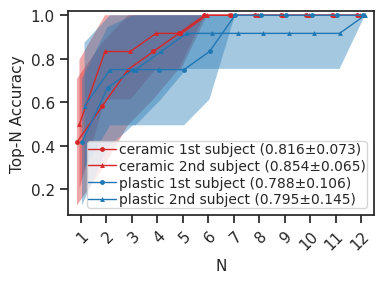

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import os

init_plot_style()
max_N = jk5_bar.shape[0]
ns = np.arange(1, max_N + 1)
markers_role = {'1st subject': 'o', '2nd subject': '^'}
role_keys = {'1st subject': 'pair1_resident', '2nd subject': 'pair2_perp'}
baseline_role = '1st subject'
baseline_role_idx = roles.index(baseline_role)
curves = []

for mat_i, mat in enumerate(surface_types):
    baseline_key = role_keys[baseline_role]
    baseline_mask = (
        (paired_samples.sample_metadata['surface_type'] == mat) &
        (paired_samples.sample_metadata[baseline_key].isin(best_model_mixed.classes_))
    ).values
    baseline_fold_matrix = extract_masked_fold_matrix(jk5_bar, baseline_mask, mat_i, baseline_role_idx)

    for role_j, role in enumerate(roles):
        role_key = role_keys[role]
        mask = (
            (paired_samples.sample_metadata['surface_type'] == mat) &
            (paired_samples.sample_metadata[role_key].isin(best_model_mixed.classes_))
        ).values
        role_stats = compute_masked_jackknife_topn_stats(jk5_bar, mask, mat_i, role_j)
        fold_matrix = role_stats['fold_matrix']

        stars = ''
        if role == '2nd subject':
            p_val = jackknife_auc_unpaired_test(
                baseline_fold_matrix,
                fold_matrix,
                alternative='greater',
            )
            star_symbol = get_significance_stars(p_val)
            stars = f' {star_symbol}' if star_symbol else ''

        curves.append({
            'label': f'{mat} {role}',
            'means': role_stats['means'],
            'se': role_stats['se'],
            'auc': role_stats['auc'],
            'se_auc': role_stats['se_auc'],
            'color': mat_color_dict[mat],
            'marker': markers_role[role],
            'stars': stars,
        })

jitter_step = 0.3 / (len(curves) - 1) if len(curves) > 1 else 0.0
fig_topn_jk_mixed, ax_topn_jk_mixed, curves, bracket_info = plot_precomputed_topn_jackknife(
    curve_data=curves,
    figsize=(4, 3),
    ns=ns,
    jitter_width=jitter_step,
    alpha_fill=0.4,
    linewidth=1,
    markersize=3.5,
    legend_loc='lower right',
    legend_kwargs=dict(fontsize=10, handletextpad=0.2, labelspacing=0.2, borderpad=0.1),
)

ax_topn_jk_mixed.set_xticks(range(1, max_N + 1))
ax_topn_jk_mixed.set_xlim(0.5, max_N + 0.5)
ax_topn_jk_mixed.set_xlabel('N', fontsize=11)
ax_topn_jk_mixed.set_ylabel('Top-N Accuracy', fontsize=11)
ax_topn_jk_mixed.set_ylim(top=1.02)
rotate_xticklabels(ax_topn_jk_mixed)
plt.tight_layout()
plt.show()

save_fig(fig_topn_jk_mixed, os.path.join(RESULTS_DIR, '201610.mixed-signal.top-n-accuracy-jk.pdf'))
